
---
date: "2026-11-13"
date-modified: last-modified
format:
  html:
    toc: true
---


# The Hawkes Process

**Prerequisites:** [Point processes and the Poisson process](point-processes-and-poisson-process.ipynb) · [Conditional intensity and compensator](conditional-intensity-and-compensator.ipynb) · [Branching processes](branching-process.ipynb)

A **Hawkes process** is a point process whose intensity jumps up after every event and then relaxes: each event raises the chance of further events in the near future. This **self-excitation** produces the clusters seen in trades and quotes, earthquakes and aftershocks, or social-media cascades. The model has two equivalent descriptions, by its intensity and as a branching (cluster) process, and almost every result below comes from switching between them.

## 1\. Definition

::: {#def-hawkes-process}
## Hawkes process
Let $\mu > 0$ and let $\varphi : [0, \infty) \to [0, \infty)$ be locally integrable. A counting process $N$ is a **(linear) Hawkes process** with **baseline intensity** $\mu$ and **excitation kernel** $\varphi$ if its [conditional intensity](conditional-intensity-and-compensator.ipynb#def-conditional-intensity) is
$$
\lambda_t = \mu + \sum_{T_i < t}\varphi(t - T_i) = \mu + \int_{[0, t)}\varphi(t - s)\, dN_s .
$$
The number
$$
\eta = \|\varphi\|_1 = \int_0^\infty \varphi(t)\, dt \in (0, \infty]
$$
is the **branching ratio**. When $\eta < \infty$ we often write $\varphi = \eta\, g$ with $g$ a probability density, so that $\eta$ measures *how much* excitation an event causes and $g$ *when* it acts.
:::

The intensity on $(T_{k-1}, T_k]$ is a deterministic function of $T_1, \dots, T_{k-1}$, so by the [hazard representation](conditional-intensity-and-compensator.ipynb#prp-hazard-representation) the conditional laws of $T_1, T_2, \dots$ are determined one after the other, and the process exists and is unique in law. It has finitely many events in every bounded interval, because $E\,N_t < \infty$ for every $t$ (@thm-hawkes-mean below, which holds for every value of $\eta$).

::: {.callout-warning}
## Notation varies
The same model appears under different letters. Here (and in most of the market microstructure literature) the intensity is $\lambda_t = \mu + \sum \varphi(t - T_i)$. Some reviews write $\lambda^*(t) = \lambda + \sum \mu(t - T_i)$, with $\lambda$ the background rate and $\mu$ the excitation function; the star stresses that the intensity is random. The branching ratio is written $\eta$, $n$ or $\|\varphi\|_1$.
:::

## 2\. The Exponential Kernel and the Markov Property

::: {#def-exponential-hawkes}
## Exponential Hawkes process
For $\alpha, \beta > 0$ the **exponential kernel** is $\varphi(t) = \alpha e^{-\beta t}$, with $\eta = \alpha/\beta$. Allowing an initial intensity $\lambda_0 > 0$ (a process that has been running before observation started), the **exponential Hawkes process** has intensity
$$
\lambda_t = \mu + (\lambda_0 - \mu)e^{-\beta t} + \sum_{T_i < t}\alpha e^{-\beta(t - T_i)} .
$$
With $\lambda_0 = \mu$ this is @def-hawkes-process.
:::

::: {#prp-exponential-markov}
## Markov property
For the exponential Hawkes process, between events $T_k < t \le T_{k+1}$,
$$
\lambda_t = \mu + \big(\lambda_{T_k} + \alpha - \mu\big)e^{-\beta(t - T_k)},
$$
that is, the intensity jumps by $\alpha$ at each event and decays exponentially to $\mu$ at rate $\beta$; in differential form $d\lambda_t = \beta(\mu - \lambda_t)\,dt + \alpha\, dN_t$. In particular the future of $(N, \lambda)$ after time $t$ depends on the past only through the current value $\lambda_{t+}$: the pair $(N_t, \lambda_t)$ is a Markov process. The compensator is
$$
\Lambda_t = \mu t + \frac{\lambda_0 - \mu}{\beta}\big(1 - e^{-\beta t}\big) + \sum_{T_i < t}\frac{\alpha}{\beta}\big(1 - e^{-\beta(t - T_i)}\big).
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-exponential-markov
For $T_k < t \le T_{k+1}$ the events before $t$ are $T_1, \dots, T_k$, so
$$
\lambda_t - \mu = e^{-\beta(t - T_k)}\Big[(\lambda_0 - \mu)e^{-\beta T_k} + \sum_{i \le k}\alpha e^{-\beta(T_k - T_i)}\Big] = e^{-\beta(t - T_k)}\big[(\lambda_{T_k} - \mu) + \alpha\big],
$$
because the bracket is $\lambda_{T_k} - \mu$ (the sum over $i < k$, evaluated at $T_k$) plus the new term $\alpha$ for $i = k$. Given $\lambda_{t+}$, this formula and the hazard representation determine the law of the future without reference to earlier events, which is the Markov property. The compensator follows by integrating each term: $\int_0^t e^{-\beta s}\,ds = (1 - e^{-\beta t})/\beta$ and $\int_{T_i}^t \alpha e^{-\beta(s - T_i)}\,ds = \frac{\alpha}{\beta}(1 - e^{-\beta(t - T_i)})$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: a temperature that is heated by events
Think of $\lambda_t$ as the temperature of the market. Every trade heats it by $\alpha$; it cools back to the background level $\mu$ with half-life $\log 2/\beta$. Hot periods produce more trades, which keep it hot: that feedback is the cluster. The Markov property makes the exponential kernel the default choice: the likelihood, simulation and moments can all be computed by recursions in $O(n)$ instead of $O(n^2)$.
:::

## 3\. Other Kernels

The shape $g$ of the kernel encodes how long the influence of an event lasts.

::: {#def-kernels}
## Common kernels

1. **Exponential:** $\varphi(t) = \alpha e^{-\beta t}$, $\eta = \alpha/\beta$; a short, memoryless influence with time scale $1/\beta$. A **sum of exponentials** $\sum_j \alpha_j e^{-\beta_j t}$ is still Markov, in the vector of the partial intensities.
2. **Power law (Omori–Utsu):** $\varphi(t) = K(t + c)^{-p}$ with $K, c > 0$, $p > 1$, and $\eta = \dfrac{K c^{1-p}}{p - 1}$. Its normalized shape $g(t) = \frac{p-1}{c}(1 + t/c)^{-p}$ is a Pareto (Lomax) density, heavy-tailed; for $p \le 2$ even the mean delay is infinite.
3. **Gamma-shaped:** $\varphi(t) = \eta\,\dfrac{t^{k-1}e^{-t/\theta}}{\Gamma(k)\theta^k}$; for $k > 1$ the excitation is *delayed*, peaking at $t = (k-1)\theta$.
:::

In seismology the power law describes the decay of aftershock rates. In high-frequency financial data the estimated kernels are also close to power laws over several decades of time, with branching ratios close to $1$; see [Hawkes processes in market microstructure](hawkes-processes-in-market-microstructure.ipynb).

## 4\. The Cluster (Immigration–Birth) Representation

::: {#def-cluster-process}
## Immigration–birth construction
Let $\mu > 0$ and $\varphi \ge 0$ be locally integrable. Construct a random set of points on $[0, \infty)$ as follows.

1. **Immigrants** arrive as a homogeneous Poisson process with rate $\mu$.
2. Every point born at time $s$ (immigrant or not) gives birth to its own **children**, an inhomogeneous Poisson process with rate $t \mapsto \varphi(t - s)$ on $(s, \infty)$, independently of everything else.
3. Children have children in the same way, and so on.

The **cluster** of an immigrant is the immigrant together with all its descendants. Let $N$ count all points of all generations.
:::

::: {#thm-cluster-representation}
## Hawkes = Poisson cluster process
The process $N$ of @def-cluster-process is a Hawkes process with baseline $\mu$ and kernel $\varphi$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-cluster-representation
Let $\mathcal{G}_t$ be the information generated by all points born up to time $t$ *together with their family labels* (who is whose child). Given $\mathcal{G}_t$, what happens after $t$ is generated by the immigrant stream and by the child streams of the points $T_i \le t$. By independent increments of each Poisson process and independence of the streams, given $\mathcal{G}_t$ their restrictions to $(t, \infty)$ are independent inhomogeneous Poisson processes with rates $\mu$ and $\varphi(\cdot - T_i)$. Until the next birth, no new stream is created, so by [superposition](point-processes-and-poisson-process.ipynb#thm-superposition) the next birth after the last one, $T_k$, is the first point of an inhomogeneous Poisson process with rate
$$
\mu + \sum_{i \le k}\varphi(t - T_i), \qquad t > T_k .
$$
The survival function of the next birth given $\mathcal{G}_{T_k}$ is therefore $\exp\big(-\int_{T_k}^t [\mu + \sum_{i\le k}\varphi(u - T_i)]\,du\big)$. This expression depends only on the birth times $T_1, \dots, T_k$, not on the family labels. Conditioning further on the coarser history $\mathcal{H}$ (event times only) averages over the labels and leaves it unchanged (by the [tower property](conditional-expectation.ipynb#thm-iterated-expectations)). Hence the conditional survival functions of $N$ with respect to its own history are those of a process with intensity $\mu + \sum_{T_i < t}\varphi(t - T_i)$, and by the [hazard representation](conditional-intensity-and-compensator.ipynb#prp-hazard-representation), $N$ is a Hawkes process. $\blacksquare$
:::

::: {.callout-note}
## Intuition: exogenous shocks and endogenous cascades
The baseline $\mu$ is the rate of **exogenous** events: news, an independent order. Each event then triggers **endogenous** events, which trigger more. Looking only at the timestamps we cannot tell immigrants from children; the intensity formula is what remains after forgetting the family tree. In estimation we can reconstruct the tree probabilistically ([EM and declustering](hawkes-estimation.ipynb#em-algorithm-and-the-branching-structure)).
:::

::: {#prp-branching-structure}
## The branching structure
Assume $\eta < \infty$ and consider the process on the whole half-line.

1. Each point has $\operatorname{Pois}(\eta)$ children, because its child process has total mass $\int_s^\infty \varphi(t - s)\,dt = \eta$. Given their number, the children's delays after the parent are i.i.d. with density $g = \varphi/\eta$.
2. The generation sizes $Z_0 = 1, Z_1, Z_2, \dots$ within one cluster form a [Galton–Watson branching process](branching-process.ipynb) with $\operatorname{Pois}(\eta)$ offspring, and $E\,Z_k = \eta^k$.
3. The cluster size $S = \sum_{k \ge 0}Z_k$ satisfies $E\,S = \dfrac{1}{1 - \eta}$ if $\eta < 1$, and $E\,S = \infty$ if $\eta \ge 1$. If $\eta \le 1$ every cluster is finite almost surely; if $\eta > 1$ a cluster is infinite with positive probability $1 - q$, where $q$ is the smallest root of $q = e^{\eta(q - 1)}$ in $[0, 1]$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-branching-structure
1. The children of a point at $s$ form an inhomogeneous Poisson process with rate $\varphi(\cdot - s)$, so their total number is Poisson with mean $\eta$; given their number they are i.i.d. with density $\varphi(t - s)/\eta$ on $(s, \infty)$ (part 3 of the [time-change theorem](point-processes-and-poisson-process.ipynb#thm-poisson-time-change), or directly by the same order-statistics computation).
2. Every member of generation $k$ has, independently of the others and of the past generations, a $\operatorname{Pois}(\eta)$ number of children: this is the definition of a Galton–Watson process. Conditioning on $Z_{k-1}$, $E[Z_k \mid Z_{k-1}] = \eta Z_{k-1}$, so by the tower property $E\,Z_k = \eta\,E\,Z_{k-1} = \eta^k$.
3. By monotone convergence $E\,S = \sum_k \eta^k$, which is $1/(1-\eta)$ for $\eta < 1$ and infinite otherwise. The extinction probability $q$ of a Galton–Watson process is the smallest fixed point in $[0, 1]$ of the offspring generating function, here $s \mapsto E\,s^{\operatorname{Pois}(\eta)} = e^{\eta(s-1)}$, and $q = 1$ if and only if the mean offspring $\eta \le 1$ ([branching processes](branching-process.ipynb)). A cluster is finite exactly when its Galton–Watson process dies out. $\blacksquare$
:::

The full law of the cluster size is known: for $\eta < 1$, $S$ has the **Borel distribution** $P(S = k) = e^{-\eta k}(\eta k)^{k-1}/k!$, with variance $\eta/(1-\eta)^3$ (stated without proof; it follows from the hitting-time theorem for random walks). We check it by simulation in §7.

::: {#cor-endogenous-fraction}
## Fraction of endogenous events
If $\eta < 1$, on average a fraction $1 - \eta$ of all events are immigrants and a fraction $\eta$ are triggered by earlier events.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-endogenous-fraction
Each immigrant brings on average $E\,S = 1/(1-\eta)$ events, one of which is the immigrant itself, so the immigrants make up $1/E\,S = 1 - \eta$ of the events. (Over a long window $[0, T]$, the clusters cut off by the edge $T$ are a vanishing fraction.) $\blacksquare$
:::

## 5\. Mean Intensity and Stationarity

::: {#thm-hawkes-mean}
## Mean intensity
Let $m(t) = E\,\lambda_t$.

1. $m$ is finite and satisfies the renewal equation
$$
m(t) = \mu + \int_0^t \varphi(t - s)\, m(s)\, ds .
$$
2. Its solution is $m(t) = \mu\big(1 + \int_0^t R(s)\,ds\big)$, where the **resolvent** $R = \sum_{k \ge 1}\varphi^{*k}$ is the sum of the convolution powers of $\varphi$ (it solves $R = \varphi + \varphi * R$).
3. If $\eta < 1$, then $m(t)$ increases to $\bar\lambda = \dfrac{\mu}{1 - \eta}$ and $E\,N_t / t \to \bar\lambda$. If $\eta \ge 1$, then $m(t) \to \infty$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-hawkes-mean
Fix a horizon $T$; replacing $\varphi$ by $\varphi\mathbf{1}_{[0,T]}$ changes nothing on $[0, T]$, so we may assume $\varphi$ integrable.

*Step 1: the resolvent.* For $c > 0$ let $\hat\varphi(c) = \int_0^\infty e^{-ct}\varphi(t)\,dt$; by dominated convergence $\hat\varphi(c) \to 0$ as $c \to \infty$, so we can fix $c$ with $\hat\varphi(c) < 1$. Since $e^{-ct}$ is multiplicative, $\int_0^\infty e^{-ct}\varphi^{*k}(t)\,dt = \hat\varphi(c)^k$, hence $\int_0^T\varphi^{*k} \le e^{cT}\hat\varphi(c)^k$. The series $R = \sum_k\varphi^{*k}$ converges in $L^1[0, T]$, and rearranging gives $R = \varphi + \varphi * R$.

*Step 2: finiteness.* Let $M_K(t) = E\,N_{t\wedge T_K} \le K$. The stopped process has intensity $\lambda_s\mathbf{1}\{s \le T_K\}$, so by [integration against $dN$](conditional-intensity-and-compensator.ipynb#cor-campbell) (with $H_s = \mathbf{1}\{s \le T_K\}$, determined by the strict past),
$$
M_K(t) = E\int_0^{t\wedge T_K}\Big(\mu + \sum_{T_i < s}\varphi(s - T_i)\Big)ds \le \mu t + E\sum_{T_i \le t\wedge T_K}\int_{T_i}^t\varphi(s - T_i)\,ds = \mu t + \int_0^t\varphi(r)\,M_K(t - r)\,dr,
$$
where the last step writes $\int_{T_i}^t\varphi(s - T_i)\,ds = \int_0^t\varphi(r)\mathbf{1}\{T_i \le t - r\}\,dr$ and uses Fubini. Iterating this inequality $k$ times, the remainder $\varphi^{*k} * M_K$ is at most $K\int_0^T\varphi^{*k} \to 0$, so
$$
M_K(t) \le \bar M(t) := \mu\int_0^t\Big(1 + \int_0^s R(r)\,dr\Big)ds < \infty .
$$
Since $M_K(t) \ge K\,P(T_K \le t)$, we get $P(T_K \le t) \to 0$: the process does not explode, $N_{t\wedge T_K} \uparrow N_t$, and by monotone convergence $E\,N_t \le \bar M(t)$.

*Step 3: the renewal equation.* Now that $E\,N_t < \infty$, the same computation without stopping gives equality, $E\,N_t = \mu t + \int_0^t\varphi(r)\,E\,N_{t-r}\,dr$. This equation has exactly one locally bounded solution: the difference $D$ of two solutions satisfies $|D| \le \varphi * |D| \le \cdots \le \varphi^{*k} * |D| \to 0$. As $\bar M$ solves it, $E\,N_t = \int_0^t m(s)\,ds$ with $m = \mu(1 + \int_0^{\cdot}R)$. Finally, by [integration against $dN$](conditional-intensity-and-compensator.ipynb#cor-campbell) with $H_s = \varphi(t - s)$, $E\,\lambda_t = \mu + \int_0^t\varphi(t - s)\,m(s)\,ds = \mu + \mu\int_0^t\big(\varphi + \varphi * R\big) = \mu\big(1 + \int_0^t R\big) = m(t)$, which proves parts 1 and 2.

*Step 4: limits.* $\int_0^\infty\varphi^{*k} = \eta^k$, so by monotone convergence $\int_0^t R \uparrow \sum_k\eta^k$, which is $\eta/(1-\eta)$ if $\eta < 1$ and $\infty$ otherwise. Hence $m(t) \uparrow \mu/(1 - \eta)$, respectively $m(t) \to \infty$, and $E\,N_t/t = \frac1t\int_0^t m \to \bar\lambda$ (a Cesàro mean). $\blacksquare$
:::

::: {#thm-hawkes-stationary}
## Stationarity
If $\eta < 1$ there is a unique stationary Hawkes process on $\mathbb{R}$ with baseline $\mu$ and kernel $\varphi$ (built from the cluster construction with immigrants on the whole line), its mean intensity is $\bar\lambda = \mu/(1 - \eta)$, and $N_t/t \to \bar\lambda$ almost surely. A process started at time $0$ converges to it as $t \to \infty$. If $\eta \ge 1$ no stationary version with finite intensity exists. (Stated without proof; the mean formula is @thm-hawkes-mean.)
:::

::: {.callout-note}
## Intuition: why $\eta < 1$
Each event causes $\eta$ children on average, hence $\eta^2$ grandchildren, and so on: an exogenous event is amplified into $1 + \eta + \eta^2 + \cdots = 1/(1-\eta)$ events. The amplification is finite only if $\eta < 1$. The mean intensity is the exogenous rate times this multiplier. As $\eta \uparrow 1$ (the **critical** regime) the multiplier explodes, clusters become enormous, and the process is dominated by its own feedback.
:::

::: {#cor-exponential-mean}
## Mean intensity for the exponential kernel
For the exponential Hawkes process with initial intensity $\lambda_0$, put $\kappa = \beta - \alpha$. Then $m' = \beta\mu - \kappa m$ and
$$
m(t) = \bar\lambda + (\lambda_0 - \bar\lambda)e^{-\kappa t}, \qquad \bar\lambda = \frac{\beta\mu}{\beta - \alpha} = \frac{\mu}{1 - \eta}\quad (\kappa \ne 0),
$$
so $m(t) \to \bar\lambda$ at rate $\kappa$ if $\alpha < \beta$, and $m$ grows like $e^{(\alpha - \beta)t}$ if $\alpha > \beta$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-exponential-mean
Taking expectations in @def-exponential-hawkes and using [integration against $dN$](conditional-intensity-and-compensator.ipynb#cor-campbell),
$$
m(t) = \mu + (\lambda_0 - \mu)e^{-\beta t} + \alpha\int_0^t e^{-\beta(t-s)}m(s)\,ds .
$$
Differentiating, $m'(t) = -\beta(\lambda_0 - \mu)e^{-\beta t} + \alpha m(t) - \beta\alpha\int_0^t e^{-\beta(t-s)}m(s)\,ds = -\beta(m(t) - \mu) + \alpha m(t) = \beta\mu - \kappa m(t)$, with $m(0) = \lambda_0$. This linear ODE has the stated solution. $\blacksquare$
:::

## 6\. Second-Order Structure

Clustering is a second-order property: it shows up in variances and covariances of counts. For the exponential kernel these can be computed exactly, using the generator of the Markov process $(N_t, \lambda_t)$.

::: {#lem-dynkin-hawkes}
## Dynkin's formula for the exponential Hawkes process
Let $f(n, x)$ be continuously differentiable in $x$ with polynomial growth, and define
$$
\mathcal{A}f(n, x) = \beta(\mu - x)\,\partial_x f(n, x) + x\big[f(n+1, x+\alpha) - f(n, x)\big].
$$
Then $E\,f(N_t, \lambda_{t+}) - E\,f(N_0, \lambda_{0}) = \int_0^t E\,\mathcal{A}f(N_s, \lambda_s)\,ds$. The same holds conditionally on $\mathcal{H}_r$ for $t \ge r$, starting from $(N_r, \lambda_{r+})$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-dynkin-hawkes
Between events, $(N, \lambda)$ moves along $\dot\lambda = \beta(\mu - \lambda)$ with $N$ fixed; at an event, $(n, x) \mapsto (n+1, x+\alpha)$. Hence, pathwise,
$$
f(N_t, \lambda_{t+}) - f(N_0, \lambda_0) = \int_0^t \beta(\mu - \lambda_s)\,\partial_x f(N_s, \lambda_s)\,ds + \sum_{T_k \le t}\big[f(N_{T_k^-} + 1, \lambda_{T_k} + \alpha) - f(N_{T_k^-}, \lambda_{T_k})\big].
$$
The summand is $H_{T_k}$ for $H_s = f(N_{s^-}+1, \lambda_s + \alpha) - f(N_{s^-}, \lambda_s)$, which is determined by the strict past ($\lambda$ is left-continuous). Taking expectations and applying [integration against $dN$](conditional-intensity-and-compensator.ipynb#cor-campbell) to the positive and negative parts of $H$ (integrable by the growth condition, since all moments of $N_t$ and $\lambda_t$ are finite) replaces the sum by $\int_0^t E[\lambda_s H_s]\,ds$, which is the jump part of $\mathcal{A}f$. $\blacksquare$
:::

::: {#thm-hawkes-second-order}
## Second-order statistics, exponential kernel
Let $N$ be the stationary exponential Hawkes process with $\alpha < \beta$; put $\kappa = \beta - \alpha$ and $\bar\lambda = \mu/(1 - \eta)$. Then:

1. $\operatorname{Var}\lambda_t = \dfrac{\alpha^2\bar\lambda}{2\kappa}$.
2. **Mean reversion:** $E[\lambda_{t+u} \mid \mathcal{H}_t] = \bar\lambda + (\lambda_{t+} - \bar\lambda)e^{-\kappa u}$ for $u \ge 0$.
3. **Covariance density:** for intervals $A$ entirely before $B$,
$$
\operatorname{Cov}\big(N(A), N(B)\big) = \int_A\int_B c(v - u)\,dv\,du, \qquad c(u) = \frac{\bar\lambda\,\alpha(2\beta - \alpha)}{2\kappa}\,e^{-\kappa u}\quad(u > 0).
$$
4. **Variance of counts:** for a window of length $\tau$,
$$
\operatorname{Var} N(t, t + \tau] = \bar\lambda\Big[\frac{\beta^2}{\kappa^2}\,\tau + \Big(1 - \frac{\beta^2}{\kappa^2}\Big)\frac{1 - e^{-\kappa\tau}}{\kappa}\Big],
$$
so the Fano factor rises from $1$ at small $\tau$ to $\beta^2/\kappa^2 = 1/(1 - \eta)^2$ as $\tau \to \infty$.
5. **Covariance of counts** in two windows of length $\tau$ separated by a gap $\delta$:
$$
\operatorname{Cov}\big(N(t, t+\tau],\, N(t + \tau + \delta, t + 2\tau + \delta]\big) = \frac{\bar\lambda\,\alpha(2\beta - \alpha)}{2\kappa^3}\big(1 - e^{-\kappa\tau}\big)^2 e^{-\kappa\delta}.
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-hawkes-second-order
Stationarity means that $E\,g(\lambda_t)$ does not depend on $t$, and $E\,\lambda_t = \bar\lambda$; note $\beta\mu = \kappa\bar\lambda$.

**1.** Apply @lem-dynkin-hawkes to $f(n, x) = x^2$: $\mathcal{A}f = 2\beta(\mu - x)x + x(2\alpha x + \alpha^2)$. In stationarity $E\,\mathcal{A}f(\lambda_t) = 0$, so $2\beta\mu\bar\lambda - 2\kappa E\lambda^2 + \alpha^2\bar\lambda = 0$, that is $E\lambda^2 = \bar\lambda^2 + \alpha^2\bar\lambda/(2\kappa)$.

**2.** Apply the conditional form of the lemma to $f = x$: $\mathcal{A}f = \beta(\mu - x) + \alpha x = \beta\mu - \kappa x$, so $g(u) = E[\lambda_{t+u} \mid \mathcal{H}_t]$ solves $g' = \beta\mu - \kappa g$, $g(0) = \lambda_{t+}$, whose solution is the stated one.

**3 and 4.** Fix $a$ and put $N_s' = N(a, s]$ for $s \ge a$. Apply the lemma (from time $a$) to $f(n, x) = n x$, for which $\mathcal{A}f = n(\beta\mu - \kappa x) + x(n\alpha + x + \alpha) - n x\alpha = n(\beta\mu - \kappa x) + x^2 + \alpha x$:
$$
\frac{d}{ds}E[N'_s\lambda_s] = \beta\mu\,E N'_s - \kappa E[N'_s\lambda_s] + E\lambda_s^2 + \alpha\bar\lambda .
$$
With $C(s) = \operatorname{Cov}(N'_s, \lambda_s) = E[N'_s\lambda_s] - \bar\lambda^2(s - a)$ and $\beta\mu = \kappa\bar\lambda$ this becomes $C' = -\kappa C + \operatorname{Var}\lambda + \alpha\bar\lambda$, $C(a) = 0$, so
$$
C(s) = \frac{c_0}{\kappa}\big(1 - e^{-\kappa(s - a)}\big), \qquad c_0 := \operatorname{Var}\lambda + \alpha\bar\lambda = \frac{\bar\lambda\,\alpha(2\beta - \alpha)}{2\kappa}.
$$
For $A = (a, s]$ and $B$ after $s$, by the martingale property and part 2 (there is almost surely no event exactly at $s$),
$$
E[N(A)N(B)] = E\Big[N(A)\int_B E[\lambda_v \mid \mathcal{H}_s]\,dv\Big] = E[N(A)]\,\bar\lambda|B| + C(s)\int_B e^{-\kappa(v - s)}\,dv .
$$
So $\operatorname{Cov}(N(A), N(B)) = \frac{c_0}{\kappa}(1 - e^{-\kappa(s-a)})\int_B e^{-\kappa(v-s)}dv = c_0\int_A\int_B e^{-\kappa(v - u)}\,dv\,du$, which is part 3.

For part 4, apply the lemma to $f = n^2$: $\mathcal{A}f = x(2n + 1)$, so $\frac{d}{ds}E[N_s'^2] = 2E[N'_s\lambda_s] + \bar\lambda$ and, subtracting $\frac{d}{ds}(\bar\lambda(s-a))^2 = 2\bar\lambda^2(s - a)$, $\frac{d}{ds}\operatorname{Var}N'_s = 2C(s) + \bar\lambda$. Integrating over a window of length $\tau$,
$$
\operatorname{Var} N(a, a+\tau] = \bar\lambda\tau + \frac{2c_0}{\kappa}\Big(\tau - \frac{1 - e^{-\kappa\tau}}{\kappa}\Big).
$$
Since $\bar\lambda + 2c_0/\kappa = \bar\lambda\big(\kappa^2 + 2\alpha\beta - \alpha^2\big)/\kappa^2 = \bar\lambda\beta^2/\kappa^2$ and $2c_0/\kappa^2 = \bar\lambda(\beta^2 - \kappa^2)/\kappa^3$, this is the stated formula. Dividing by $E\,N = \bar\lambda\tau$ and letting $\tau \to \infty$ gives the Fano limit $\beta^2/\kappa^2 = 1/(1-\eta)^2$.

**5.** By part 3 with $A = (t, t+\tau]$ and $B = (t+\tau+\delta, t+2\tau+\delta]$: $c_0\int_A e^{-\kappa(t + \tau - u)}du \cdot e^{-\kappa\delta}\int_B e^{-\kappa(v - t - \tau - \delta)}dv = c_0\big(\frac{1 - e^{-\kappa\tau}}{\kappa}\big)^2e^{-\kappa\delta}$. $\blacksquare$
:::

For a general kernel with $\eta < 1$ the same long-window limit holds: $\operatorname{Var}N(0, \tau]/\tau \to \bar\lambda/(1 - \eta)^2 = \mu/(1-\eta)^3$ (stated without proof; it is the value at frequency $0$ of the spectral density $\bar\lambda/|1 - \hat\varphi(\omega)|^2$ of the process). These moment formulas are also the basis of [estimation from binned counts](hawkes-estimation.ipynb#method-of-moments-for-binned-data).

::: {.callout-note}
## Intuition: what the formulas say
The intensity reverts to its mean at rate $\kappa = \beta - \alpha$, *slower* than the kernel's own decay rate $\beta$: each decaying jump keeps creating new jumps. Counts over windows longer than $1/\kappa$ fluctuate $1/(1-\eta)$ times more (in standard deviation) than Poisson counts with the same mean. Near criticality, $\kappa \to 0$, so correlations last very long and fluctuations are huge.
:::

## 7\. Simulation on Mock Data

The simulator below generates an exponential Hawkes process exactly, event by event; it is derived in [Simulating Hawkes processes](hawkes-simulation.ipynb#exact-simulation-for-the-exponential-kernel). We start with $\mu = 0.5$, $\alpha = 1$, $\beta = 2$ (so $\eta = 1/2$ and $\bar\lambda = 1$).

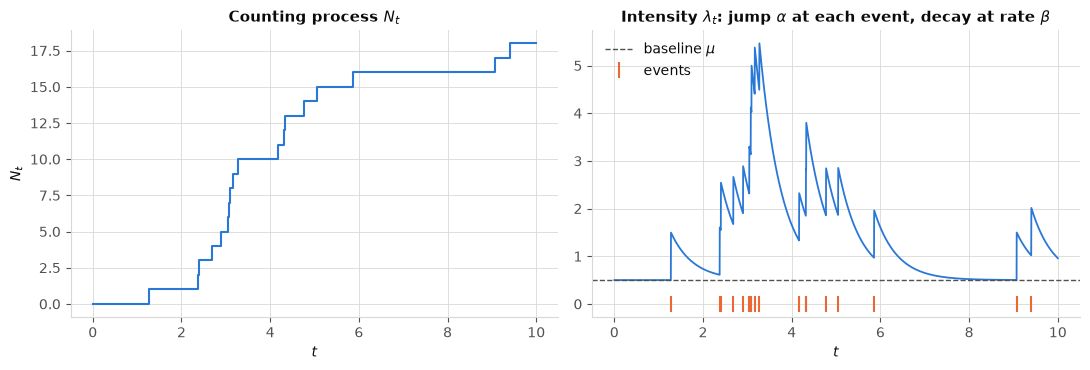

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from scipy import stats

def hawkes_exp(mu, alpha, beta, T, rng, lam0=None):
    """Exact simulation of an exponential Hawkes process on (0, T]."""
    t, excess, ev = 0.0, (0.0 if lam0 is None else lam0 - mu), []   # excess = lambda_{t+} - mu
    while True:
        e1 = rng.exponential(1 / mu)                                # next immigrant
        e2 = np.inf                                                 # next event driven by the excess
        if excess > 0:
            D = 1 + beta * np.log(rng.random()) / excess
            if D > 0:
                e2 = -np.log(D) / beta
        w = min(e1, e2); t += w
        if t > T:
            return np.array(ev)
        excess = excess * np.exp(-beta * w) + alpha
        ev.append(t)

def intensity(ev, grid, mu, alpha, beta):
    """lambda_t on a grid (left-continuous: only events strictly before t count)."""
    d = grid[:, None] - ev[None, :]
    return mu + (alpha * np.exp(-beta * np.where(d > 0, d, np.inf))).sum(1)

rng = np.random.default_rng(18)
mu, alpha, beta, T = 0.5, 1.0, 2.0, 10.0
ev = hawkes_exp(mu, alpha, beta, T, rng)
grid = np.linspace(0, T, 3000)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].step(np.r_[0, ev, T], np.r_[0, np.arange(1, len(ev) + 1), len(ev)], where="post", color=BLUE)
ax[0].set(title="Counting process $N_t$", xlabel="$t$", ylabel="$N_t$")
ax[1].plot(grid, intensity(ev, grid, mu, alpha, beta), color=BLUE, lw=1.3)
ax[1].axhline(mu, color=MUTED, ls="--", lw=1, label=r"baseline $\mu$")
ax[1].plot(ev, np.zeros(len(ev)), "|", color=ORANGE, ms=12, mew=1.5, label="events")
ax[1].set(title=r"Intensity $\lambda_t$: jump $\alpha$ at each event, decay at rate $\beta$", xlabel="$t$"); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()


The following animation builds the same picture event by event: each event lifts the intensity by $\alpha$, the intensity relaxes toward $\mu$, and a high intensity makes the next event come sooner.

In [2]:

from la_manim import *

class SelfExcitation(Scene):
    def construct(self):
        mu, alpha, beta, T = 0.5, 1.0, 2.0, 10.0
        ev = [1.06, 1.25, 1.41, 1.52, 1.63, 1.76, 2.05, 2.47, 2.58, 4.05, 4.71, 7.82, 9.02, 9.25, 9.41]
        ax = Axes(x_range=[0, T, 1], y_range=[0, 6, 1], x_length=8.6, y_length=3.1,
                  axis_config={"color": C_MUTED, "stroke_width": 1.6, "include_tip": False},
                  x_axis_config={"numbers_to_include": range(0, 11, 2), "font_size": 22},
                  y_axis_config={"numbers_to_include": range(0, 7, 2), "font_size": 22}).move_to([0.2, -0.1, 0])
        base = DashedLine(ax.c2p(0, mu), ax.c2p(T, mu), color=C_FAINT, stroke_width=2)
        lab = MathTex(r"\mu", color=C_MUTED).scale(0.7).next_to(base, LEFT, buff=0.1)
        self.add(ax, base, lab, caption(r"\lambda_t=\mu+\sum_{T_i<t}\alpha e^{-\beta(t-T_i)}", corner=UL, scale=0.62))
        lam = lambda t: mu + sum(alpha * np.exp(-beta * (t - s)) for s in ev if s < t)
        tk = ValueTracker(0.0)
        curve = always_redraw(lambda: ax.plot(lambda t: lam(t), x_range=[0, max(tk.get_value(), 1e-3), 0.01],
                                              color=C_BLUE, stroke_width=3, use_smoothing=False))
        self.add(curve)
        prev = 0.0
        for s in ev + [T]:
            self.play(tk.animate.set_value(s), run_time=0.35 + 0.35 * (s - prev), rate_func=linear)
            if s < T:
                tick = Line(ax.c2p(s, 0), ax.c2p(s, 0.35), color=C_ORANGE, stroke_width=4)
                self.play(Create(tick), Flash(ax.c2p(s, lam(s + 1e-6)), color=C_ORANGE, line_length=0.15,
                                               flash_radius=0.2), run_time=0.25)
            prev = s
        self.add(text_caption(r"each event raises the rate by $\alpha$; it relaxes back to $\mu$ at rate $\beta$", corner=DL))
        self.wait(1.5)

# manim exports its own BLUE, RED, ...: restore the palette of the static figures
BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
show(SelfExcitation)


**Clustering compared with a Poisson process.** A long Hawkes path with $\eta = 0.8$ and a Poisson path with the same mean rate $\bar\lambda = 1$. The total numbers of events are similar, but the Hawkes events come in bursts separated by long quiet stretches.

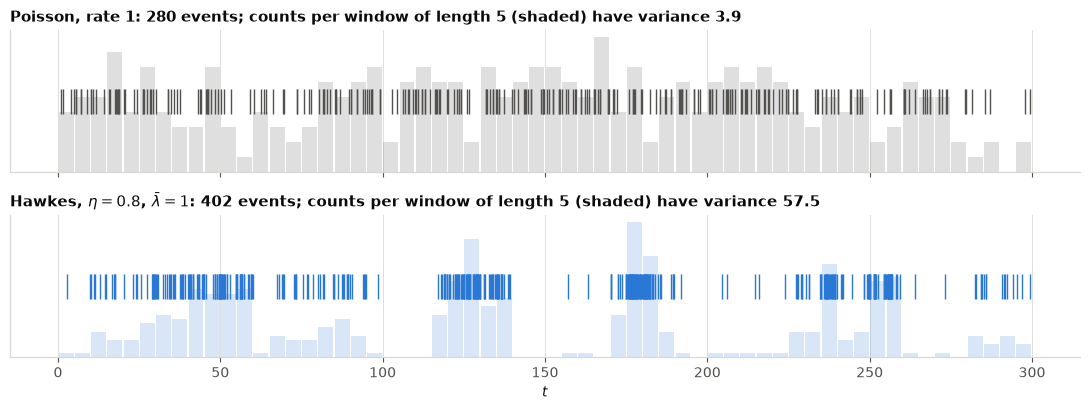

In [3]:

rng = np.random.default_rng(8)
T = 300.0
hk = hawkes_exp(0.2, 0.8, 1.0, T, rng)                  # eta = 0.8, mean rate 0.2 / 0.2 = 1
po = np.sort(rng.uniform(0, T, rng.poisson(T)))
fig, ax = plt.subplots(2, 1, figsize=(11, 4.2), sharex=True)
for a, e, c, name in [(ax[0], po, MUTED, "Poisson, rate 1"), (ax[1], hk, BLUE, r"Hawkes, $\eta = 0.8$, $\bar\lambda = 1$")]:
    a.plot(e, np.zeros(len(e)), "|", color=c, ms=18, mew=1)
    cnt = np.bincount((e // 5).astype(int), minlength=60)[:60]
    a2 = a.twinx(); a2.bar(np.arange(60) * 5 + 2.5, cnt, width=4.6, color=c, alpha=0.18); a2.set_yticks([]); a2.grid(False)
    a.set_yticks([]); a.set_title(f"{name}: {len(e)} events; counts per window of length 5 (shaded) have variance {cnt.var():.1f}", loc="left")
ax[1].set_xlabel("$t$")
plt.tight_layout(); plt.show()


**Kernels.** Exponential, power-law and gamma kernels, all with $\eta = 0.5$, on linear and log–log scales. The power law starts lower but dominates at long lags.

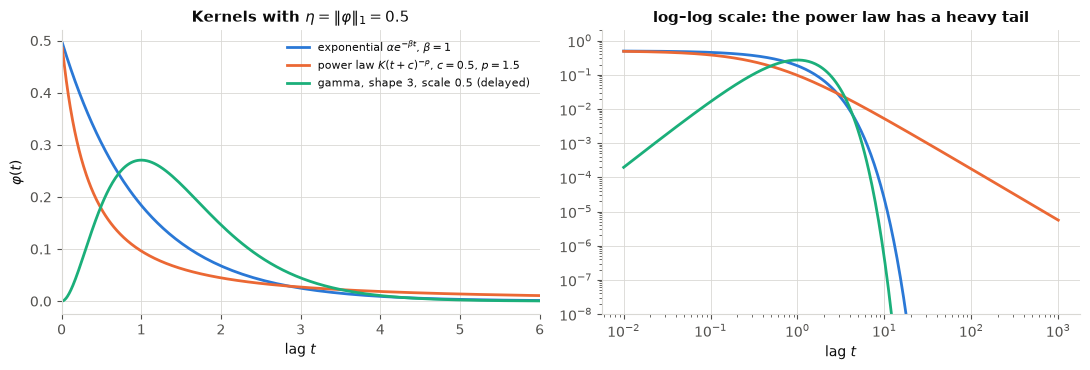

In [4]:

from scipy.special import gamma as G
t = np.logspace(-2, 3, 400)
kers = {
    r"exponential $\alpha e^{-\beta t}$, $\beta = 1$": 0.5 * np.exp(-t),
    r"power law $K(t + c)^{-p}$, $c = 0.5$, $p = 1.5$": 0.5 * (1.5 - 1) / 0.5 * (1 + t / 0.5) ** (-1.5),
    r"gamma, shape 3, scale 0.5 (delayed)": 0.5 * t ** 2 * np.exp(-t / 0.5) / (G(3) * 0.5 ** 3),
}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, k), c in zip(kers.items(), [BLUE, ORANGE, AQUA]):
    ax[0].plot(t, k, color=c, lw=2, label=name); ax[1].loglog(t, k, color=c, lw=2)
ax[0].set(xlim=(0, 6), title=r"Kernels with $\eta = \|\varphi\|_1 = 0.5$", xlabel="lag $t$", ylabel=r"$\varphi(t)$"); ax[0].legend(fontsize=8)
ax[1].set(ylim=(1e-8, 2), title="log–log scale: the power law has a heavy tail", xlabel="lag $t$")
plt.tight_layout(); plt.show()


**The family tree.** Simulating through @def-cluster-process records who triggered whom. Below, $\mu = 0.25$, exponential kernel with $\eta = 0.8$ and $\beta = 1$ on $[0, 60]$: immigrants on the bottom row, each generation one row higher, with an arc from every child to its parent. Projecting all rows onto the time axis gives the Hawkes process.

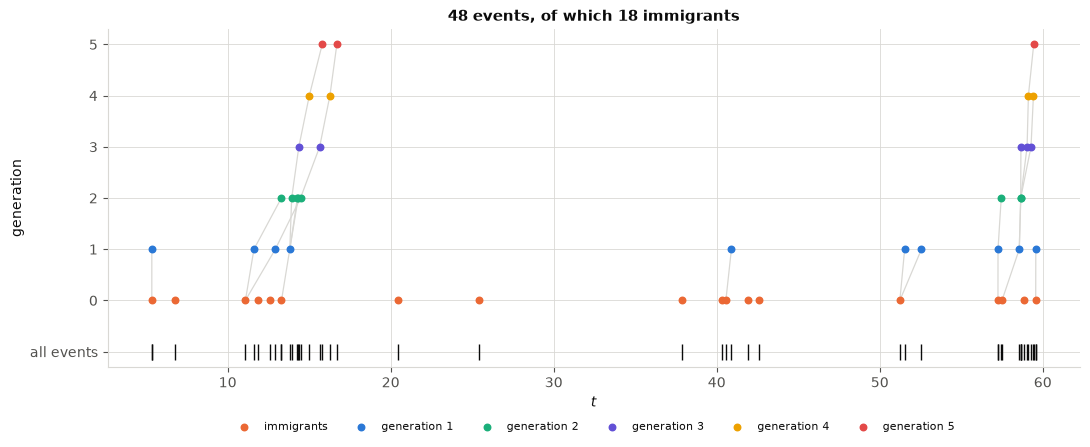

fraction of immigrants over 100 paths on [0, 2000]: 0.201   (theory 1 - eta = 0.200)


In [5]:

def hawkes_cluster(mu, eta, beta, T, rng):
    """Immigration-birth simulation; returns times, parent index (-1 = immigrant), generation."""
    times = list(rng.uniform(0, T, rng.poisson(mu * T)))
    parent = [-1] * len(times); gen = [0] * len(times)
    i = 0
    while i < len(times):                       # every point (of every generation) has children
        kids = times[i] + rng.exponential(1 / beta, rng.poisson(eta))
        for k in kids[kids <= T]:
            times.append(k); parent.append(i); gen.append(gen[i] + 1)
        i += 1
    return np.array(times), np.array(parent), np.array(gen)

rng = np.random.default_rng(21)
tm, par, gen = hawkes_cluster(0.25, 0.8, 1.0, 60.0, rng)
cols = [ORANGE, BLUE, AQUA, VIOLET, YELLOW, RED, MUTED]
fig, ax = plt.subplots(figsize=(11, 4.6))
for i in np.where(par >= 0)[0]:
    j = par[i]
    ax.plot([tm[j], tm[i]], [gen[j], gen[i]], color=GRID, lw=0.9, zorder=1)
for g in range(gen.max() + 1):
    s = gen == g
    ax.scatter(tm[s], gen[s], s=22, color=cols[min(g, 6)], zorder=2, label="immigrants" if g == 0 else (f"generation {g}" if g < 6 else None))
ax.plot(tm, np.full(len(tm), -1.0), "|", color=INK, ms=12)
ax.set(yticks=[-1] + list(range(gen.max() + 1)), yticklabels=["all events"] + [str(g) for g in range(gen.max() + 1)],
       xlabel="$t$", ylabel="generation", title=f"{len(tm)} events, of which {np.sum(gen == 0)} immigrants")
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13))
plt.tight_layout(); plt.show()
# the immigrant fraction of a single short path is very noisy (Var S = eta/(1-eta)^3 = 100): average over long paths
fr = [np.mean(hawkes_cluster(0.25, 0.8, 1.0, 2000.0, rng)[2] == 0) for _ in range(100)]
print(f"fraction of immigrants over 100 paths on [0, 2000]: {np.mean(fr):.3f}   (theory 1 - eta = 0.200)")


The animation shows the same mechanism: immigrants arrive, each event spawns its children a random delay later, and finally all generations collapse onto one time axis, where the family structure is no longer visible.

In [6]:

class ClusterCascade(Scene):
    def construct(self):
        rng = np.random.default_rng(5)
        T, mu, eta, beta = 10.0, 0.35, 0.75, 1.3
        tm, par, gen = hawkes_cluster(mu, eta, beta, T, rng)
        G = int(gen.max())
        ax = NumberLine(x_range=[0, T, 1], length=7.6, color=C_MUTED, include_numbers=True, font_size=22).to_edge(DOWN, buff=1.0).shift(RIGHT * 0.6)
        ys = lambda g: ax.n2p(0)[1] + 0.8 + 0.68 * g
        pos = lambda i: np.array([ax.n2p(tm[i])[0], ys(gen[i]), 0])
        cols = [C_ORANGE, C_BLUE, C_AQUA, C_VIOLET, C_YELLOW, C_RED]
        rows = VGroup(*[Text("immigrants" if g == 0 else f"gen {g}", color=C_MUTED).scale(0.32)
                        .next_to([ax.n2p(0)[0] - 0.15, ys(g), 0], LEFT, buff=0) for g in range(G + 1)])
        self.add(ax, caption(r"\text{immigrants} \sim \mathrm{Pois}(\mu),\quad \text{children} \sim \mathrm{Pois}(\eta)", corner=UR, scale=0.6))
        self.play(FadeIn(rows), run_time=0.5)
        dots = {}
        for g in range(G + 1):
            anims = []
            for i in np.where(gen == g)[0]:
                d = Dot(pos(i), radius=0.07, color=cols[min(g, 5)]); dots[i] = d
                if par[i] >= 0:
                    arc = ArcBetweenPoints(pos(par[i]), pos(i), angle=-0.6, color=C_GRID, stroke_width=2)
                    anims.append(Create(arc)); self.add_foreground_mobject(dots[par[i]])
                anims.append(GrowFromCenter(d))
            self.play(*anims, run_time=0.9)
        self.wait(0.5)
        self.play(*[d.animate.move_to(ax.n2p(tm[i])).set_color(C_INK) for i, d in dots.items()],
                  *[FadeOut(m) for m in self.mobjects if isinstance(m, ArcBetweenPoints)], FadeOut(rows), run_time=1.6)
        self.add(text_caption(r"forgetting the family tree leaves one Hawkes process", corner=DL))
        self.wait(1.5)

# manim exports its own BLUE, RED, ...: restore the palette of the static figures
BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
show(ClusterCascade)


**Cluster sizes.** Clusters on the infinite horizon are Galton–Watson trees with $\operatorname{Pois}(\eta)$ offspring. For $\eta = 0.6$ we compare the simulated cluster sizes with the Borel distribution and with $E\,S = 1/(1-\eta) = 2.5$.

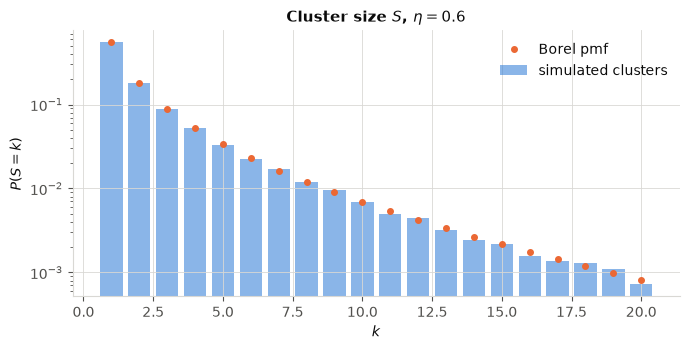

E S: simulated 2.500, theory 2.500;  Var S: simulated 9.43, theory 9.37


In [7]:

from scipy.special import gammaln
rng = np.random.default_rng(2)
eta = 0.6
def cluster_size(eta, rng):
    alive, total = 1, 1
    while alive:
        alive = rng.poisson(eta * alive)        # children of the whole current generation
        total += alive
    return total
S = np.array([cluster_size(eta, rng) for _ in range(100000)])
k = np.arange(1, 21)
borel = np.exp(-eta * k + (k - 1) * np.log(eta * k) - gammaln(k + 1))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(k, np.bincount(S, minlength=22)[1:21] / len(S), color=BLUE, alpha=0.55, label="simulated clusters")
ax.plot(k, borel, "o", color=ORANGE, ms=4, label="Borel pmf")
ax.set_yscale("log"); ax.set(title=r"Cluster size $S$, $\eta = 0.6$", xlabel="$k$", ylabel="$P(S = k)$"); ax.legend()
plt.tight_layout(); plt.show()
print(f"E S: simulated {S.mean():.3f}, theory {1/(1-eta):.3f};  Var S: simulated {S.var():.2f}, theory {eta/(1-eta)**3:.2f}")


**Mean intensity and explosion.** Averages of $\lambda_t$ over 4000 paths started at $\lambda_0 = \mu = 0.5$, against @cor-exponential-mean: for $\beta = 2$ and $\alpha = 1$ the mean rises to $\bar\lambda = 1$ at rate $\kappa = 1$; for $\alpha = 2.4 > \beta$ it grows like $e^{0.4t}$.

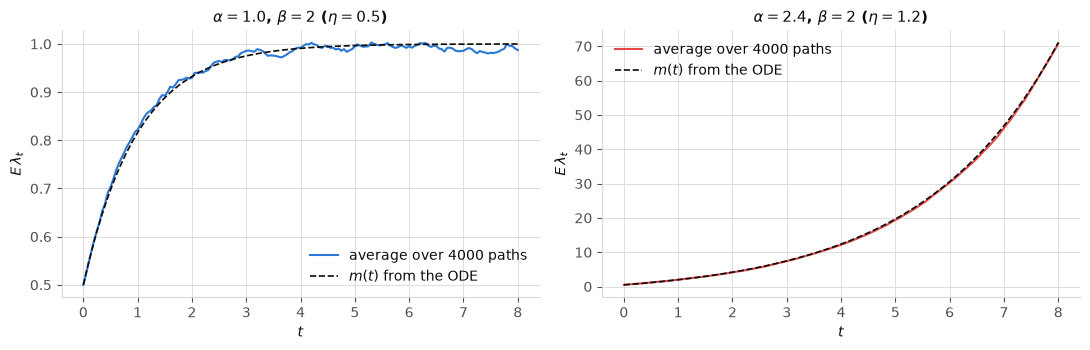

In [8]:

rng = np.random.default_rng(6)
grid = np.linspace(0, 8, 161)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, alpha_, c in [(ax[0], 1.0, BLUE), (ax[1], 2.4, RED)]:
    lam = np.mean([intensity(hawkes_exp(0.5, alpha_, 2.0, 8.0, rng), grid, 0.5, alpha_, 2.0) for _ in range(4000)], axis=0)
    kap = 2.0 - alpha_; lbar = 2.0 * 0.5 / kap
    a.plot(grid, lam, color=c, lw=1.5, label="average over 4000 paths")
    a.plot(grid, lbar + (0.5 - lbar) * np.exp(-kap * grid), color=INK, ls="--", lw=1.2, label="$m(t)$ from the ODE")
    a.set(title=rf"$\alpha = {alpha_}$, $\beta = 2$ ($\eta = {alpha_/2:.1f}$)", xlabel="$t$", ylabel=r"$E\,\lambda_t$"); a.legend()
plt.tight_layout(); plt.show()


**Fano factor.** Variance-to-mean ratio of counts in windows of length $\tau$, estimated from one long path ($T = 2 \times 10^5$) for $\eta = 0.5$ and $\eta = 0.8$ (with $\beta = 1$ and $\bar\lambda = 1$), against part 4 of @thm-hawkes-second-order. The Poisson value is $1$; the limits are $1/(1-\eta)^2 = 4$ and $25$.

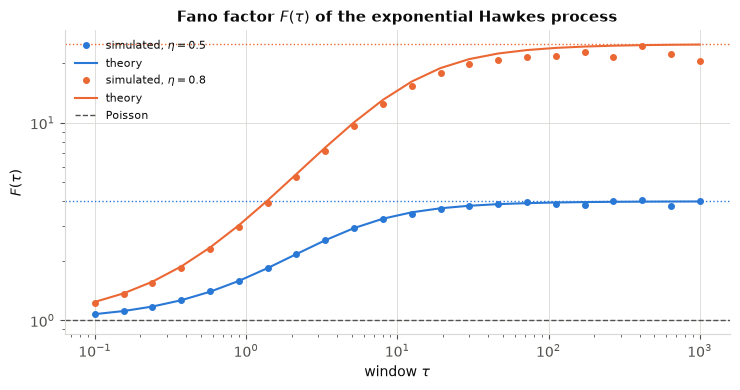

In [9]:

rng = np.random.default_rng(9)
T = 2e5
taus = np.logspace(-1, 3, 22)
fig, ax = plt.subplots(figsize=(7.5, 4))
for eta, c in [(0.5, BLUE), (0.8, ORANGE)]:
    a_, b_ = eta, 1.0; mu_ = 1 - eta; kap = b_ - a_; lbar = mu_ / (1 - eta)
    e = hawkes_exp(mu_, a_, b_, T, rng)
    e = e[e > 100] - 100                                    # drop the start-up transient
    emp = []
    for tau in taus:
        nb = int((T - 100) // tau); cnt = np.bincount((e // tau).astype(int), minlength=nb)[:nb]
        emp.append(cnt.var() / cnt.mean())
    th = (b_**2 / kap**2 * taus + (1 - b_**2 / kap**2) * (1 - np.exp(-kap * taus)) / kap) / taus
    ax.semilogx(taus, emp, "o", color=c, ms=4, label=rf"simulated, $\eta = {eta}$")
    ax.semilogx(taus, th, color=c, lw=1.5, label="theory")
    ax.axhline(1 / (1 - eta) ** 2, color=c, ls=":", lw=1)
ax.axhline(1, color=MUTED, ls="--", lw=1, label="Poisson")
ax.set(yscale="log", title=r"Fano factor $F(\tau)$ of the exponential Hawkes process", xlabel=r"window $\tau$", ylabel=r"$F(\tau)$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Approaching criticality.** Three paths with the same mean rate $\bar\lambda = 1$ and $\beta = 1$ but increasing branching ratio. As $\eta \to 1$ almost all events are endogenous, and the path alternates between near-silence and violent bursts.

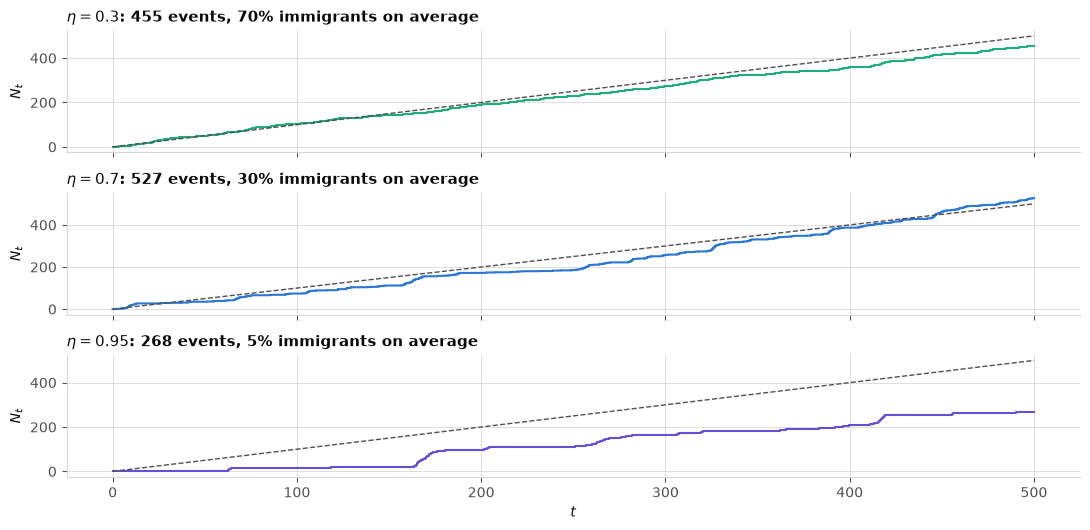

In [10]:

rng = np.random.default_rng(13)
T = 500.0
fig, ax = plt.subplots(3, 1, figsize=(11, 5.4), sharex=True)
for a, eta, c in zip(ax, [0.3, 0.7, 0.95], [AQUA, BLUE, VIOLET]):
    e = hawkes_exp(1 - eta, eta, 1.0, T, rng)
    a.step(np.r_[0, e, T], np.r_[0, np.arange(1, len(e) + 1), len(e)], where="post", color=c)
    a.plot([0, T], [0, T], color=MUTED, ls="--", lw=1)
    a.set_title(rf"$\eta = {eta}$: {len(e)} events, {100*(1-eta):.0f}% immigrants on average", loc="left"); a.set_ylabel("$N_t$")
ax[-1].set_xlabel("$t$")
plt.tight_layout(); plt.show()